In [2]:
# =====================================================================
# CELL 1: NẠP DỮ LIỆU, KHỬ TRÙNG HASH, LỌC HOÀ PHIẾU & CHIA TẬP STRATIFY
# =====================================================================
import os
import random
import sys
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler


def set_seed(seed=42):
    """Cố định toàn bộ hạt giống ngẫu nhiên (seed) để đảm bảo tái lập kết quả 100%."""
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


KAGGLE_INPUT = Path("/kaggle/input")


def find_unique_file(filename):
    matches = list(KAGGLE_INPUT.rglob(filename)) if KAGGLE_INPUT.exists() else []
    if not matches and Path(filename).exists():
        return Path(filename).resolve()
    if len(matches) != 1:
        paths = "\n".join(str(path) for path in matches) or "(không tìm thấy)"
        raise FileNotFoundError(
            f"Cần tìm thấy đúng 1 file '{filename}', nhưng tìm thấy {len(matches)}:\n{paths}"
        )
    return matches[0]


DATA_UTILS = find_unique_file("data_utils.py")
PROJECT_DIR = DATA_UTILS.parent
IMG_CSV = find_unique_file("fer2013.csv")
LABEL_CSV = find_unique_file("fer2013new.csv")

sys.path.insert(0, str(PROJECT_DIR))

print("Thư mục mã nguồn:", PROJECT_DIR)
print("File ảnh:", IMG_CSV)
print("File nhãn:", LABEL_CSV)

from data_utils import load_fer2013_csv
from dataset import FER2013Dataset
from models import CustomCNN
from eval_utils import (
    SoftWeightedKLDivLoss,
    compute_epoch_metrics,
    summarize_multi_seed_results,
    plot_learning_curves,
    denormalize_image,
    ten_crop_inference,
    generate_gradcam,
    evaluate_private_test,
)

# 1. Khử trùng theo MD5 hash + Bỏ ảnh hoà phiếu (drop_ties=True) + Chia Stratified 80/10/10
set_seed(42)
(
    (X_train, y_train_soft, y_train_hard),
    (X_val, y_val_soft, y_val_hard),
    (X_test, y_test_soft, y_test_hard),
) = load_fer2013_csv(
    IMG_CSV,
    LABEL_CSV,
    return_soft_labels=True,
    use_stratify=True,
    drop_ties=True,
    random_state=42,
)

EMOTION_DICT = {
    0: "Neutral",
    1: "Happiness",
    2: "Surprise",
    3: "Sadness",
    4: "Anger",
    5: "Disgust",
    6: "Fear",
    7: "Contempt",
}

Thư mục mã nguồn: /kaggle/input/datasets/alceanh19/fermodels/HL
File ảnh: /kaggle/input/datasets/alceanh19/datasetfer/fer2013.csv
File nhãn: /kaggle/input/datasets/alceanh19/fer-2013/fer2013new.csv
=== THỐNG KÊ DỮ LIỆU ĐẦU VÀO ===
Ảnh trong fer2013.csv: 35,887 dòng
Nhãn trong fer2013new.csv: 35,887 dòng
Ghép ảnh và nhãn theo thứ tự dòng (hai file không có ID chung).

=== KẾT QUẢ KHỬ TRÙNG, LỌC NHIỄU VÀ CHIA TẬP ===
Phương pháp chia tập: Stratified Split (80/10/10, random_state=42)
Bị loại do trùng hash pixel (Deduplication): 1,853
Bỏ qua do Usage không thuộc 3 tập: 0
Bị loại vì không còn phiếu cảm xúc > 1: 168
Bị loại vì unknown/NF >= cảm xúc cao nhất: 481
Bị loại vì hoà phiếu cao nhất (Ties): 1,417
Tổng ảnh sạch được giữ trong 3 tập: 31,968

Train: 25,574 ảnh
  Phân phối: Neutral=9,191 (35.9%), Happiness=7,169 (28.0%), Surprise=2,817 (11.0%), Sadness=3,220 (12.6%), Anger=2,279 (8.9%), Disgust=154 (0.6%), Fear=586 (2.3%), Contempt=158 (0.6%)
Validation: 3,197 ảnh
  Phân phối: Neutral=1

In [3]:
# =====================================================================
# CELL 2: HÀM HUẤN LUYỆN CUSTOM_CNN CHO 1 SEED (LẤY VAL MACRO-F1 LÀM CHỈ SỐ CHÍNH)
# =====================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Đang huấn luyện trên thiết bị:", device)

# Trọng số lớp dạng căn bậc hai nghịch đảo (Square-Root Class Weight)
class_counts = np.bincount(y_train_hard, minlength=8)
sqrt_inv_weights = 1.0 / np.sqrt(np.maximum(class_counts, 1))
norm_class_weights = sqrt_inv_weights / sqrt_inv_weights.mean()
print("Trọng số lớp căn bậc hai (chuẩn hoá):", np.round(norm_class_weights, 3))


def create_dataloaders(seed, batch_size=64, use_oversampling=True):
    set_seed(seed)
    train_dataset = FER2013Dataset(X_train, y_train_soft, is_train=True)
    val_dataset = FER2013Dataset(X_val, y_val_soft, is_train=False)
    test_dataset = FER2013Dataset(X_test, y_test_hard, is_train=False)

    g = torch.Generator()
    g.manual_seed(seed)

    if use_oversampling:
        sample_weights = sqrt_inv_weights[y_train_hard]
        sampler = WeightedRandomSampler(
            weights=torch.DoubleTensor(sample_weights),
            num_samples=len(sample_weights),
            replacement=True,
            generator=g,
        )
        train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            sampler=sampler,
            drop_last=True,
        )
    else:
        train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            generator=g,
            drop_last=True,
        )

    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, val_loader, test_loader


def train_and_evaluate_custom_cnn(
    seed,
    num_epochs=75,
    ft_epochs=20,
    patience=15,
    use_oversampling=True,
    use_class_weight_in_loss=False,
    focal_gamma=0.0,
):
    set_seed(seed)
    train_loader, val_loader, test_loader = create_dataloaders(
        seed, batch_size=64, use_oversampling=use_oversampling
    )

    model = CustomCNN(num_classes=8).to(device)

    loss_weights = norm_class_weights if use_class_weight_in_loss else None
    criterion = SoftWeightedKLDivLoss(class_weights=loss_weights, gamma=focal_gamma).to(device)

    optimizer = optim.SGD(
        model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4, nesterov=True
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=4
    )

    ckpt_path = f"best_custom_cnn_seed{seed}.pth"
    best_val_macro_f1 = 0.0
    patience_counter = 0

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": [],
        "train_macro_f1": [], "val_macro_f1": [], "val_weighted_f1": [],
    }

    print(f"\n>>> [CustomCNN | Seed {seed}] BẮT ĐẦU GIAI ĐOẠN 1 ({num_epochs} Epochs)...")
    for epoch in range(num_epochs):
        model.train()
        running_loss, total_train = 0.0, 0
        train_preds, train_targets = [], []

        for images, soft_labels in train_loader:
            images, soft_labels = images.to(device), soft_labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, soft_labels)
            loss.backward()
            optimizer.step()

            bs = images.size(0)
            running_loss += loss.item() * bs
            total_train += bs
            train_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            train_targets.extend(soft_labels.argmax(dim=1).cpu().numpy())

        train_loss = running_loss / total_train
        train_acc, train_macro_f1, _ = compute_epoch_metrics(train_targets, train_preds)

        # --- VALIDATION ---
        model.eval()
        val_running_loss, total_val = 0.0, 0
        val_preds, val_targets = [], []

        with torch.no_grad():
            for images, soft_labels in val_loader:
                images, soft_labels = images.to(device), soft_labels.to(device)
                outputs = model(images)
                v_loss = criterion(outputs, soft_labels)
                bs = images.size(0)
                val_running_loss += v_loss.item() * bs
                total_val += bs
                val_preds.extend(outputs.argmax(dim=1).cpu().numpy())
                val_targets.extend(soft_labels.argmax(dim=1).cpu().numpy())

        val_loss = val_running_loss / total_val
        val_acc, val_macro_f1, val_weighted_f1 = compute_epoch_metrics(val_targets, val_preds)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["train_macro_f1"].append(train_macro_f1)
        history["val_macro_f1"].append(val_macro_f1)
        history["val_weighted_f1"].append(val_weighted_f1)

        # Điều chỉnh LR và lưu model tốt nhất dựa trên Val Macro-F1 (chỉ số chính)
        scheduler.step(val_macro_f1)
        current_lr = optimizer.param_groups[0]["lr"]

        if val_macro_f1 > best_val_macro_f1:
            best_val_macro_f1 = val_macro_f1
            torch.save(model.state_dict(), ckpt_path)
            patience_counter = 0
            flag = "-> Lưu best!"
        else:
            patience_counter += 1
            flag = ""

        if (epoch + 1) % 5 == 0 or flag:
            print(
                f"Epoch [{epoch+1:02d}/{num_epochs}] | LR: {current_lr:.5f} | "
                f"Loss: {train_loss:.4f}/{val_loss:.4f} | "
                f"Val Macro-F1: {val_macro_f1*100:.2f}% | Val Acc: {val_acc*100:.2f}% {flag}"
            )

        if patience_counter >= patience:
            print(f"Dừng sớm (Early Stopping) tại Epoch {epoch + 1}!")
            break

    phase1_ran = len(history["train_loss"])

    # --- GIAI ĐOẠN 2: FINE-TUNING VỚI COSINE ANNEALING ---
    print(f">>> [CustomCNN | Seed {seed}] GIAI ĐOẠN 2: FINE-TUNING ({ft_epochs} Epochs)...")
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    optimizer_ft = optim.SGD(
        model.parameters(), lr=5e-4, momentum=0.9, weight_decay=1e-4, nesterov=True
    )
    scheduler_ft = optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=ft_epochs)

    for epoch in range(ft_epochs):
        model.train()
        running_loss, total_train = 0.0, 0
        train_preds, train_targets = [], []

        for images, soft_labels in train_loader:
            images, soft_labels = images.to(device), soft_labels.to(device)
            optimizer_ft.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, soft_labels)
            loss.backward()
            optimizer_ft.step()

            bs = images.size(0)
            running_loss += loss.item() * bs
            total_train += bs
            train_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            train_targets.extend(soft_labels.argmax(dim=1).cpu().numpy())

        train_loss = running_loss / total_train
        train_acc, train_macro_f1, _ = compute_epoch_metrics(train_targets, train_preds)

        model.eval()
        val_running_loss, total_val = 0.0, 0
        val_preds, val_targets = [], []
        with torch.no_grad():
            for images, soft_labels in val_loader:
                images, soft_labels = images.to(device), soft_labels.to(device)
                outputs = model(images)
                v_loss = criterion(outputs, soft_labels)
                bs = images.size(0)
                val_running_loss += v_loss.item() * bs
                total_val += bs
                val_preds.extend(outputs.argmax(dim=1).cpu().numpy())
                val_targets.extend(soft_labels.argmax(dim=1).cpu().numpy())

        val_loss = val_running_loss / total_val
        val_acc, val_macro_f1, val_weighted_f1 = compute_epoch_metrics(val_targets, val_preds)
        scheduler_ft.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["train_macro_f1"].append(train_macro_f1)
        history["val_macro_f1"].append(val_macro_f1)
        history["val_weighted_f1"].append(val_weighted_f1)

        if val_macro_f1 > best_val_macro_f1:
            best_val_macro_f1 = val_macro_f1
            torch.save(model.state_dict(), ckpt_path)
            print(
                f"FT Epoch [{epoch+1:02d}/{ft_epochs}] | Val Macro-F1: {val_macro_f1*100:.2f}% "
                f"| Val Acc: {val_acc*100:.2f}% -> Lưu best mới!"
            )

    # --- ĐÁNH GIÁ TRÊN TẬP TEST ---
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            preds = model(images).argmax(dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    metrics = evaluate_private_test(
        y_true, y_pred, EMOTION_DICT, title_prefix=f"CustomCNN (Seed {seed})"
    )
    return model, metrics, history, phase1_ran, ckpt_path

Đang huấn luyện trên thiết bị: cuda
Trọng số lớp căn bậc hai (chuẩn hoá): [0.297 0.336 0.536 0.502 0.596 2.293 1.176 2.264]



>>> [CustomCNN | Seed 42] BẮT ĐẦU GIAI ĐOẠN 1 (75 Epochs)...
Epoch [01/75] | LR: 0.01000 | Loss: 2.5634/1.2814 | Val Macro-F1: 18.80% | Val Acc: 45.36% -> Lưu best!
Epoch [02/75] | LR: 0.01000 | Loss: 1.6256/1.1056 | Val Macro-F1: 26.27% | Val Acc: 52.89% -> Lưu best!
Epoch [03/75] | LR: 0.01000 | Loss: 1.3217/0.9210 | Val Macro-F1: 35.46% | Val Acc: 60.53% -> Lưu best!
Epoch [04/75] | LR: 0.01000 | Loss: 1.1238/0.8066 | Val Macro-F1: 38.57% | Val Acc: 64.56% -> Lưu best!
Epoch [05/75] | LR: 0.01000 | Loss: 1.0311/0.7299 | Val Macro-F1: 42.72% | Val Acc: 67.47% -> Lưu best!
Epoch [06/75] | LR: 0.01000 | Loss: 0.9458/0.6556 | Val Macro-F1: 47.17% | Val Acc: 68.94% -> Lưu best!
Epoch [07/75] | LR: 0.01000 | Loss: 0.8721/0.6546 | Val Macro-F1: 49.09% | Val Acc: 70.22% -> Lưu best!
Epoch [08/75] | LR: 0.01000 | Loss: 0.8180/0.5823 | Val Macro-F1: 51.52% | Val Acc: 72.85% -> Lưu best!
Epoch [10/75] | LR: 0.01000 | Loss: 0.7103/0.5348 | Val Macro-F1: 51.73% | Val Acc: 74.10% -> Lưu best!
Ep

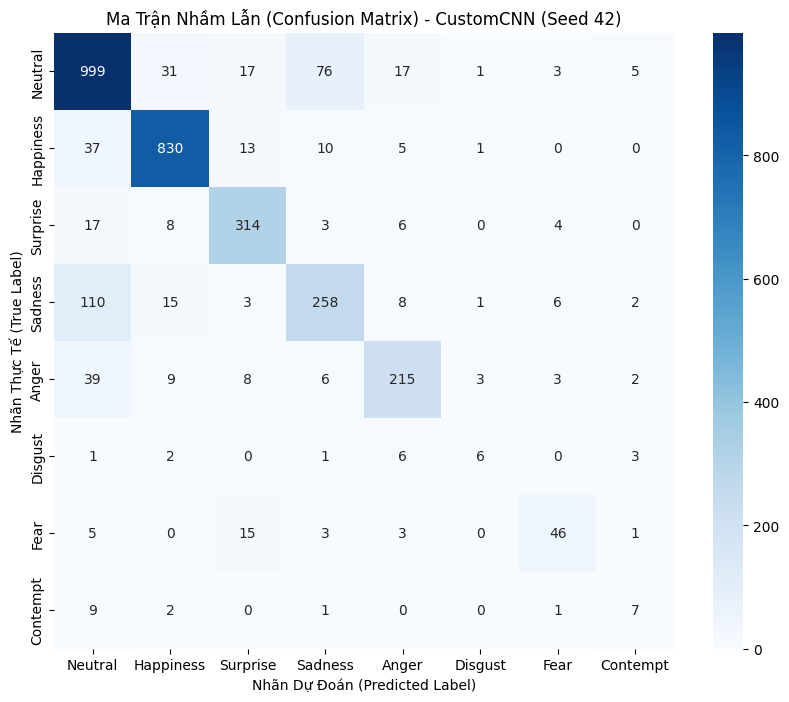


>>> [CustomCNN | Seed 100] BẮT ĐẦU GIAI ĐOẠN 1 (75 Epochs)...
Epoch [01/75] | LR: 0.01000 | Loss: 2.4833/1.2162 | Val Macro-F1: 20.22% | Val Acc: 49.70% -> Lưu best!
Epoch [02/75] | LR: 0.01000 | Loss: 1.5489/1.0334 | Val Macro-F1: 28.83% | Val Acc: 55.99% -> Lưu best!
Epoch [03/75] | LR: 0.01000 | Loss: 1.2832/0.8588 | Val Macro-F1: 36.61% | Val Acc: 63.87% -> Lưu best!
Epoch [04/75] | LR: 0.01000 | Loss: 1.1152/0.7847 | Val Macro-F1: 40.62% | Val Acc: 66.56% -> Lưu best!
Epoch [05/75] | LR: 0.01000 | Loss: 1.0025/0.6894 | Val Macro-F1: 47.28% | Val Acc: 68.91% -> Lưu best!
Epoch [06/75] | LR: 0.01000 | Loss: 0.9104/0.6370 | Val Macro-F1: 49.53% | Val Acc: 71.04% -> Lưu best!
Epoch [08/75] | LR: 0.01000 | Loss: 0.7917/0.5723 | Val Macro-F1: 52.99% | Val Acc: 73.48% -> Lưu best!
Epoch [10/75] | LR: 0.01000 | Loss: 0.7050/0.5371 | Val Macro-F1: 52.37% | Val Acc: 74.98% 
Epoch [11/75] | LR: 0.01000 | Loss: 0.6843/0.4979 | Val Macro-F1: 56.03% | Val Acc: 75.91% -> Lưu best!
Epoch [12/75]

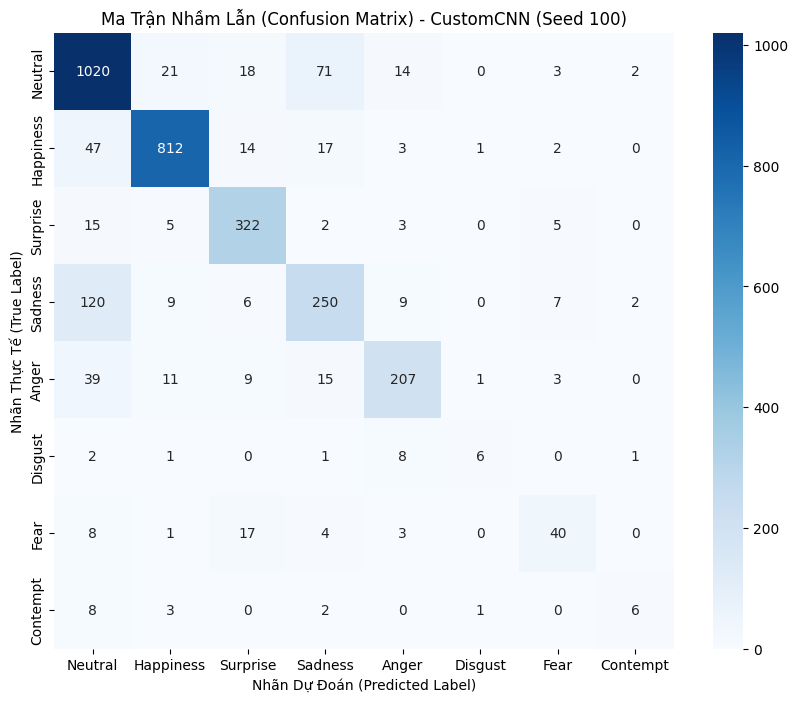


>>> [CustomCNN | Seed 2026] BẮT ĐẦU GIAI ĐOẠN 1 (75 Epochs)...
Epoch [01/75] | LR: 0.01000 | Loss: 2.4922/1.2750 | Val Macro-F1: 20.39% | Val Acc: 46.79% -> Lưu best!
Epoch [02/75] | LR: 0.01000 | Loss: 1.5174/1.0471 | Val Macro-F1: 29.99% | Val Acc: 56.08% -> Lưu best!
Epoch [03/75] | LR: 0.01000 | Loss: 1.2457/0.9292 | Val Macro-F1: 35.75% | Val Acc: 62.65% -> Lưu best!
Epoch [04/75] | LR: 0.01000 | Loss: 1.0919/0.7854 | Val Macro-F1: 40.59% | Val Acc: 65.94% -> Lưu best!
Epoch [05/75] | LR: 0.01000 | Loss: 0.9819/0.7162 | Val Macro-F1: 42.77% | Val Acc: 67.50% -> Lưu best!
Epoch [06/75] | LR: 0.01000 | Loss: 0.8943/0.6807 | Val Macro-F1: 47.75% | Val Acc: 69.47% -> Lưu best!
Epoch [07/75] | LR: 0.01000 | Loss: 0.8430/0.6203 | Val Macro-F1: 49.70% | Val Acc: 71.41% -> Lưu best!
Epoch [09/75] | LR: 0.01000 | Loss: 0.7560/0.6225 | Val Macro-F1: 51.04% | Val Acc: 71.47% -> Lưu best!
Epoch [10/75] | LR: 0.01000 | Loss: 0.7415/0.5532 | Val Macro-F1: 53.61% | Val Acc: 73.22% -> Lưu best!


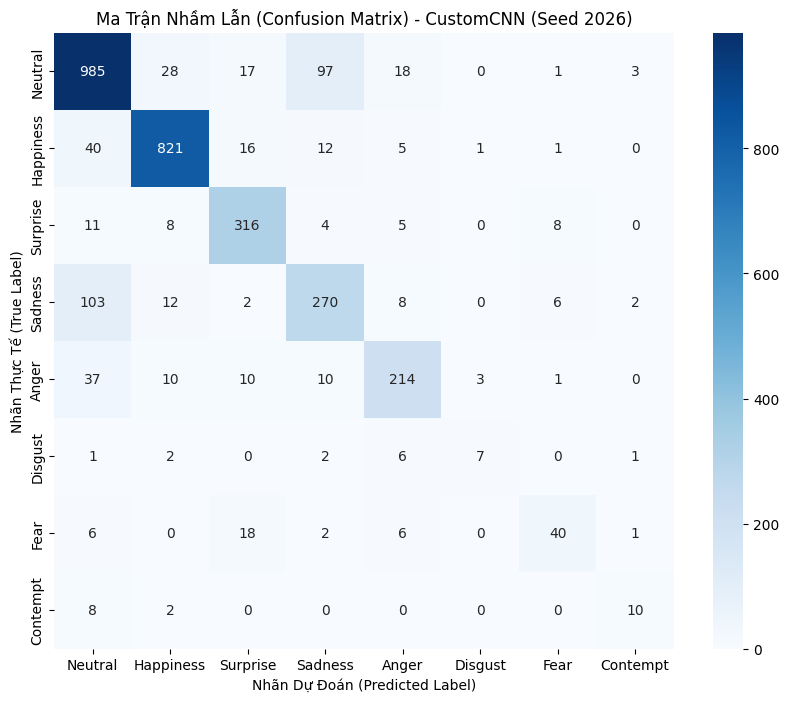


 TỔNG HỢP KẾT QUẢ 3 LẦN CHẠY (SEEDS) - MÔ HÌNH: CustomCNN (3 Seeds)
  • Macro F1 (Chính) : 69.68% ± 1.48%
  • Accuracy         : 83.42% ± 0.22%
  • Weighted F1      : 83.19% ± 0.24%
  • Recall Disgust   : 33.33% ± 3.04%
  • Recall Contempt  : 38.33% ± 10.41%



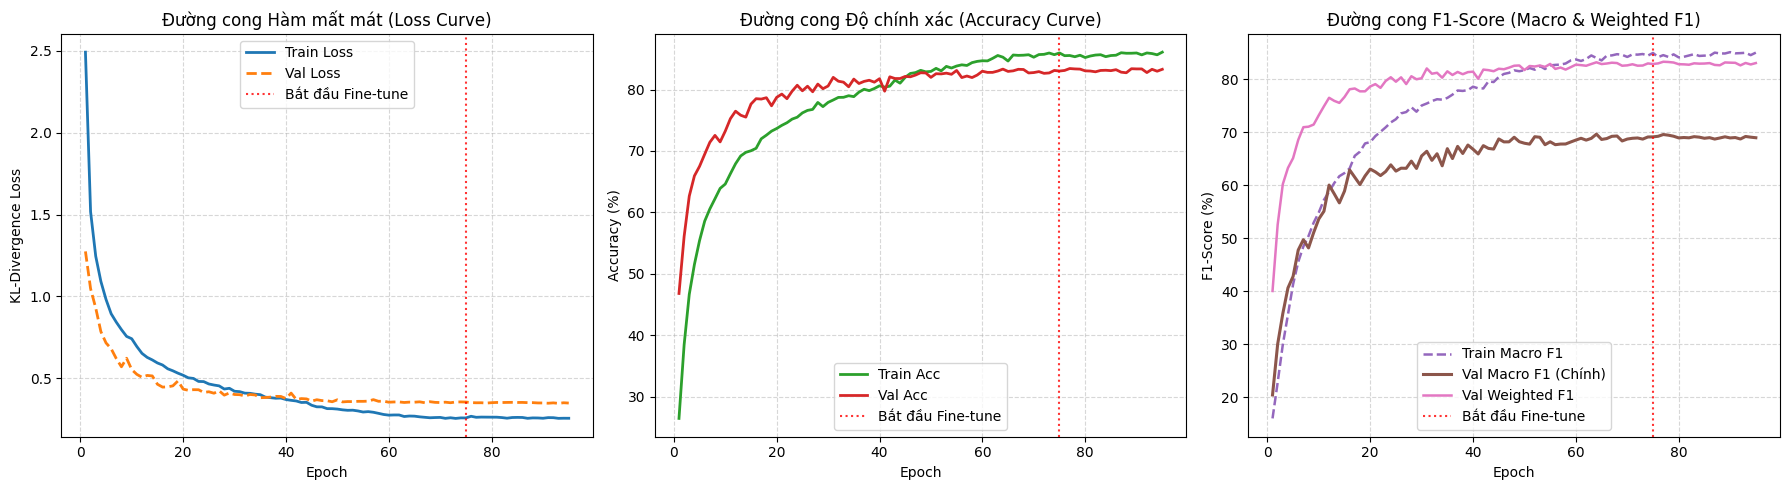

In [4]:
# =====================================================================
# CELL 3: CHẠY 3 SEEDS CHO CUSTOM_CNN & BÁO CÁO TRUNG BÌNH ± ĐỘ LỆCH CHUẨN
# =====================================================================
SEEDS = [42, 100, 2026]
custom_cnn_results = []
best_custom_model = None
best_custom_f1 = -1.0

for seed in SEEDS:
    model_run, metrics_run, hist_run, p1_epochs, ckpt = train_and_evaluate_custom_cnn(
        seed=seed,
        num_epochs=75,
        ft_epochs=20,
        patience=15,
        use_oversampling=True,
        use_class_weight_in_loss=False,
        focal_gamma=0.0,
    )
    custom_cnn_results.append(metrics_run)
    if metrics_run["macro_f1"] > best_custom_f1:
        best_custom_f1 = metrics_run["macro_f1"]
        best_custom_model = model_run
        torch.save(model_run.state_dict(), "best.pth")
        best_custom_history = (hist_run, p1_epochs)

summary_custom_cnn = summarize_multi_seed_results(
    custom_cnn_results, model_name="CustomCNN (3 Seeds)"
)
plot_learning_curves(best_custom_history[0], phase1_epochs=best_custom_history[1])

=== TỔNG HỢP CHỈ SỐ TRÊN TẬP CUSTOMCNN TEN-CROP ===
Macro F1 (Chỉ số chính): 70.76% | Accuracy: 84.02% | Weighted F1: 83.72%
Recall lớp hiếm -> Disgust: 36.84% | Contempt: 35.00%

=== BÁO CÁO KIỂM ĐỊNH CHI TIẾT (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

     Neutral     0.8255    0.8895    0.8563      1149
   Happiness     0.9353    0.9196    0.9274       896
    Surprise     0.8342    0.9006    0.8661       352
     Sadness     0.7084    0.6452    0.6753       403
       Anger     0.8214    0.7263    0.7709       285
     Disgust     0.6364    0.3684    0.4667        19
        Fear     0.7368    0.5753    0.6462        73
    Contempt     0.6364    0.3500    0.4516        20

    accuracy                         0.8402      3197
   macro avg     0.7668    0.6719    0.7076      3197
weighted avg     0.8378    0.8402    0.8372      3197



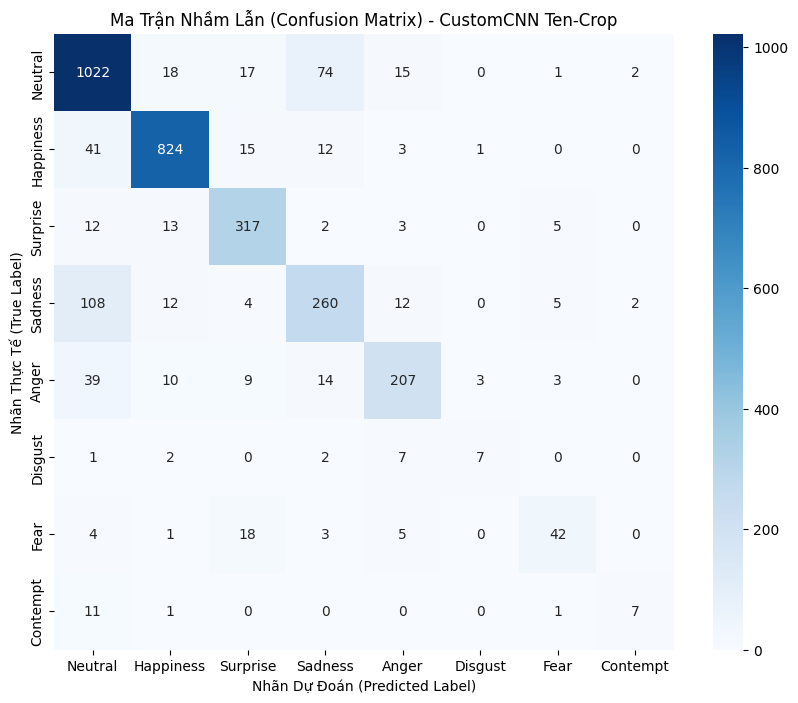

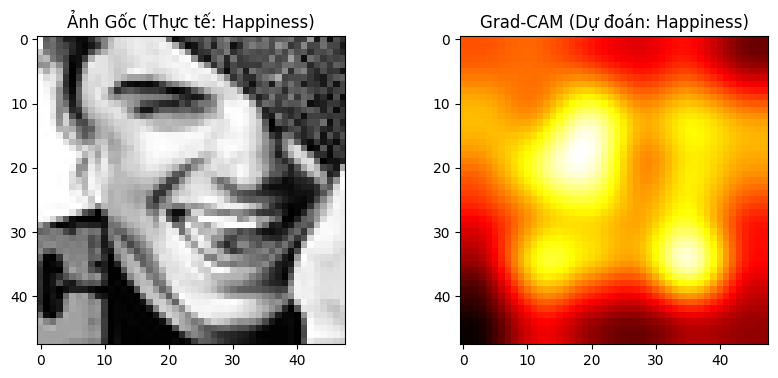

In [7]:
# =====================================================================
# CELL 4: KIỂM ĐỊNH TEN-CROP AVERAGING & TRỰC QUAN HOÁ GRAD-CAM TRÊN CUSTOM_CNN
# =====================================================================
import matplotlib.pyplot as plt

best_custom_model.load_state_dict(torch.load("best.pth", map_location=device, weights_only=True))
best_custom_model.eval()

_, _, test_loader = create_dataloaders(seed=42, batch_size=64, use_oversampling=False)
y_true_tc, y_pred_tc = [], []

for images, labels in test_loader:
    for i in range(images.size(0)):
        pred_label, _ = ten_crop_inference(best_custom_model, images[i])
        y_true_tc.append(labels[i].item())
        y_pred_tc.append(pred_label)

evaluate_private_test(y_true_tc, y_pred_tc, EMOTION_DICT, title_prefix="CustomCNN Ten-Crop")

test_dataset = FER2013Dataset(X_test, y_test_hard, is_train=False)
sample_img = test_dataset[0][0]
sample_label = test_dataset[0][1].item()
saliency, pred_class = generate_gradcam(best_custom_model, sample_img)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(denormalize_image(sample_img), cmap="gray")
plt.title(f"Ảnh Gốc (Thực tế: {EMOTION_DICT[sample_label]})")
plt.subplot(1, 2, 2)
plt.imshow(saliency, cmap="hot")
plt.title(f"Grad-CAM (Dự đoán: {EMOTION_DICT[pred_class]})")
plt.show()